In [1]:
import joblib
from dask.distributed import Client as DaskClient
from matplotlib import colors

%matplotlib inline


from utils import (
    BBOX,
    BBOX_GDF,
    DATETIME,
    classes,
    load_data,
    predict,
)

In [2]:
%reload_ext autoreload
%autoreload 2

## Find and load data

Load data and set up your array to use for prediction

In [3]:
BBOX_GDF.explore()

In [4]:
merged = load_data(BBOX, DATETIME)

Found Sentinel-2 items: 4
Found DEM items: 1
Found Sentinel-1 items: 4


In [5]:
merged

<xarray.Dataset> Size: 2GB
Dimensions:        (y: 3370, x: 5567)
Coordinates:
  * y              (y) float64 27kB -1.98e+06 -1.98e+06 ... -2.014e+06
  * x              (x) float64 45kB 3.124e+06 3.124e+06 ... 3.179e+06 3.179e+06
    spatial_ref    int32 4B 3832
    time           datetime64[us] 8B 2022-01-01
Data variables: (12/29)
    blue           (y, x) uint16 38MB dask.array<chunksize=(2048, 2048), meta=np.ndarray>
    green          (y, x) uint16 38MB dask.array<chunksize=(2048, 2048), meta=np.ndarray>
    red            (y, x) uint16 38MB dask.array<chunksize=(2048, 2048), meta=np.ndarray>
    rededge1       (y, x) uint16 38MB dask.array<chunksize=(2048, 2048), meta=np.ndarray>
    rededge2       (y, x) uint16 38MB dask.array<chunksize=(2048, 2048), meta=np.ndarray>
    rededge3       (y, x) uint16 38MB dask.array<chunksize=(2048, 2048), meta=np.ndarray>
    ...             ...
    northness      (y, x) float32 75MB dask.array<chunksize=(2048, 2048), meta=np.ndarray>
    eastness       (y, x) float32 75MB dask.array<chunksize=(2048, 2048), meta=np.ndarray>
    elevation_std  (y, x) float32 75MB dask.array<chunksize=(2052, 2052), meta=np.ndarray>
    mean_vv        (y, x) float32 75MB dask.array<chunksize=(2048, 2048), meta=np.ndarray>
    mean_vh        (y, x) float32 75MB dask.array<chunksize=(2048, 2048), meta=np.ndarray>
    mean_vv_vh     (y, x) float32 75MB dask.array<chunksize=(2048, 2048), meta=np.ndarray>

In [6]:
loaded_model = joblib.load("test_model.dump")

In [7]:
loaded_data = merged.compute()

/Users/wj/Projects/dep/minerals-model/.venv/lib/python3.15/site-packages/rasterio/warp.py:390: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dest = _reproject(


## Run ML classifier

In [8]:
# Create local dask cluster to improve data load time. Only run this once.
dask_client = DaskClient(n_workers=1, threads_per_worker=16, memory_limit="16GB")

/Users/wj/Projects/dep/minerals-model/.venv/lib/python3.15/site-packages/distributed/node.py:195: UserWarning: Port 8787 is already in use.
Perhaps you already have a cluster running?
Hosting the HTTP server on port 64145 instead
  warnings.warn(


In [9]:
predicted = predict(loaded_model, loaded_data)

In [10]:
predicted

<xarray.Dataset> Size: 94MB
Dimensions:        (y: 3370, x: 5567)
Coordinates:
  * y              (y) float64 27kB -1.98e+06 -1.98e+06 ... -2.014e+06
  * x              (x) float64 45kB 3.124e+06 3.124e+06 ... 3.179e+06 3.179e+06
    spatial_ref    int32 4B 3832
    time           datetime64[us] 8B 2022-01-01
Data variables:
    lulc           (y, x) int8 19MB dask.array<chunksize=(3370, 5567), meta=np.ndarray>
    probabilities  (y, x) float32 75MB dask.array<chunksize=(3370, 5567), meta=np.ndarray>

/Users/wj/Projects/dep/minerals-model/.venv/lib/python3.15/site-packages/distributed/client.py:3429: UserWarning: Sending large graph of size 2.03 GiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(
/Users/wj/Projects/dep/minerals-model/.venv/lib/python3.15/site-packages/sklearn/ensemble/_base.py:174: UserWarning: Inside a Dask worker with daemon=True, setting n_jobs=1.
Possible work-arounds:
- dask.config.set({'distributed.worker.daemon': False})
- set the environment variable DASK_DISTRIBUTED__WORKER__DAEMON=False
before creating your Dask cluster.
  n_jobs = min(effective_n_jobs(n_jobs), n_estimators)


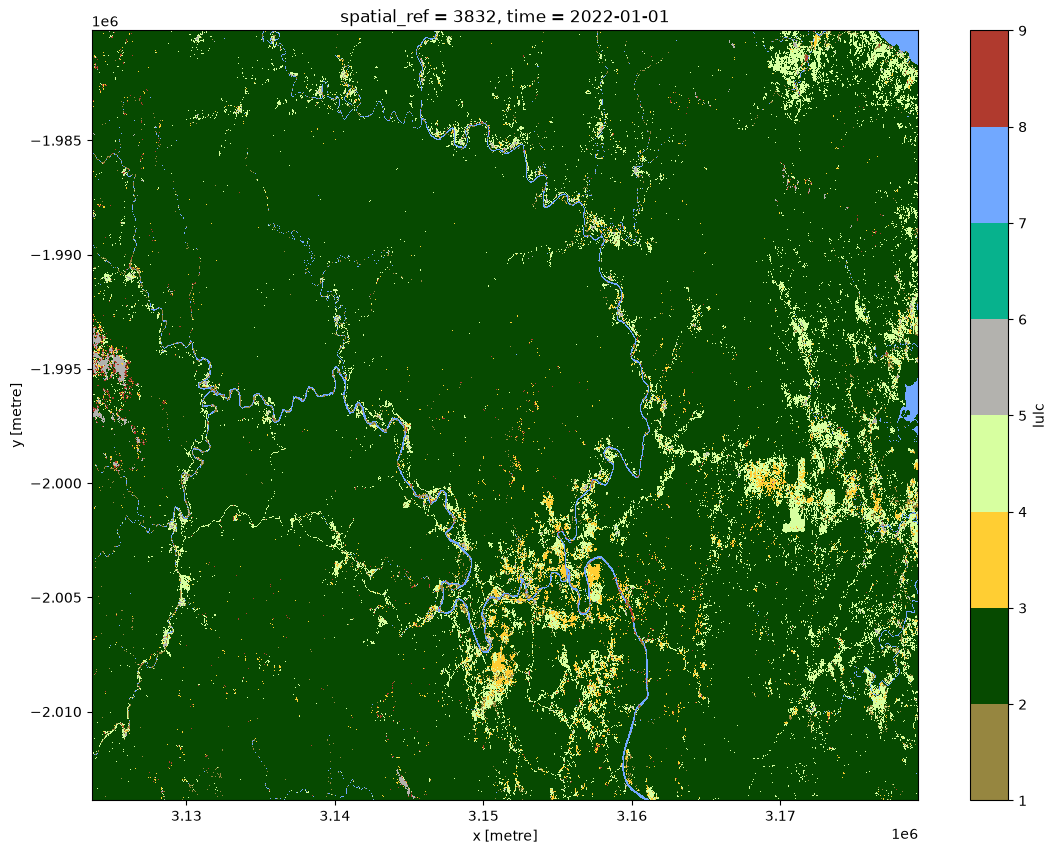

In [11]:
values_list = [c[0] for c in classes]
color_list = [c[2] for c in classes]

# Build a listed colormap.
c_map = colors.ListedColormap(color_list)
bounds = values_list + [9]
norm = colors.BoundaryNorm(bounds, c_map.N)

predicted.lulc.plot.imshow(cmap=c_map, norm=norm, size=10)

In [ ]:
# Write GeoTIFF
predicted.lulc.odc.write_cog(f"lulc_{DATETIME}.tif", overwrite=True)

/Users/wj/Projects/dep/minerals-model/.venv/lib/python3.15/site-packages/sklearn/ensemble/_base.py:174: UserWarning: Inside a Dask worker with daemon=True, setting n_jobs=1.
Possible work-arounds:
- dask.config.set({'distributed.worker.daemon': False})
- set the environment variable DASK_DISTRIBUTED__WORKER__DAEMON=False
before creating your Dask cluster.
  n_jobs = min(effective_n_jobs(n_jobs), n_estimators)
